# UNIVERSIDAD NACIONAL MAYOR DE SAN MARCOS
## Facultad de Ingeniería de Sistemas e Informática – E.P. Ingeniería de Software
**Curso:** Inteligencia Artificial
**Docente:** Prof. Juan Gamarra Moreno
**Laboratorio N° 3:** Búsqueda informada con Greedy Best-First Search y A*

**Alumno:** Purisaca Moquillaza, Joseph Francis — Código: 23200290
**Fecha:** 22 de Noviembre de 2026

Se implementan BFS, DFS, costo uniforme, Greedy Best-First Search y A* sobre la misma lista de adyacencia, con métricas
de nodos expandidos, generados y tamaño máximo de la frontera. Las respuestas a las preguntas y la declaración de uso de IA
están en el informe PDF; aquí se incluye un resumen de cada una junto a su evidencia.

## Preparación del entorno

In [1]:
import os, csv, heapq
from collections import deque
import matplotlib.pyplot as plt

print(sorted(os.listdir('datos')))
os.makedirs('figuras', exist_ok=True)    # carpeta para la gráfica del paso 10

['heuristica_lima.csv', 'heuristica_trujillo.csv', 'rutas_peru_norte.csv', 'rutas_peru_sur.csv']


## Paso 1. Cargar y explorar los datos
Funciones de lectura de la plantilla (sin modificar):

In [2]:
def leer_aristas(ruta):
    """Lee el CSV de tramos tal como viene (sin limpiar).
    Devuelve una lista de diccionarios con las claves origen, destino, distancia_km."""
    with open(ruta, newline='', encoding='utf-8') as f:
        return [dict(fila) for fila in csv.DictReader(f)]


def leer_heuristica(ruta):
    """Lee el CSV de heurística y devuelve {ciudad: h_km} (nombre sin espacios)."""
    H = {}
    with open(ruta, newline='', encoding='utf-8') as f:
        for fila in csv.DictReader(f):
            H[fila['ciudad'].strip()] = int(fila['h_km'])
    return H

In [3]:
filas = leer_aristas('datos/rutas_peru_sur.csv')
H = leer_heuristica('datos/heuristica_lima.csv')

print('Filas leidas:', len(filas))
for f in filas:
    print(repr(f['origen']), '|', repr(f['destino']), '|',
          repr(f['distancia_km']))

print('Ciudades en la heuristica:', len(H))

Filas leidas: 16
'Cusco' | 'Abancay' | '195'
'Abancay' | 'Andahuaylas' | '138'
'Abancay' | 'Puquio' | '350'
'Andahuaylas' | 'Ayacucho' | '260'
'Ayacucho' | 'Huancavelica' | '245'
'Ayacucho' | 'Pisco' | '320'
'Huancavelica' | 'Huancayo' | '147'
'Huancayo' | 'La Oroya' | '125'
'La Oroya' | 'Lima' | '187'
'Puquio' | 'Nazca' | '155'
'Nasca ' | 'Ica' | '145'
'Ica' | 'Pisco' | '75'
'Pisco' | 'Chincha' | '60'
'Chincha' | 'Lima' | '200'
'Chincha' | 'Lima' | '200'
' Lima' | 'La Oroya' | ''
Ciudades en la heuristica: 13


**Anomalías detectadas (las 4 de la Tabla 4).** Se leyeron **16 filas**, pero el grafo real solo tiene 14 tramos:

| N° | Anomalía | Dónde aparece |
|---|---|---|
| 1 | Variante de nombre para la misma ciudad | `'Puquio' \| 'Nazca'`: en el resto del archivo la ciudad se llama **Nasca** |
| 2 | Espacios en blanco al inicio o al final | `'Nasca '` (espacio al final) y `' Lima'` (espacio al inicio) |
| 3 | Fila duplicada | `'Chincha' \| 'Lima' \| '200'` aparece dos veces |
| 4 | Valor faltante en `distancia_km` | `' Lima' \| 'La Oroya' \| ''`, que además repite el tramo La Oroya–Lima |

`repr()` hace visibles los espacios (`'Nasca '`, `' Lima'`) y la cadena vacía `''`, que con `print()` pasarían desapercibidos.

## Paso 2. Limpiar los datos y construir el grafo

In [4]:
ALIAS = {
    'nazca': 'Nasca',
}


def normalizar(nombre):
    """R1 + R2: quita espacios sobrantes y aplica el diccionario ALIAS."""
    nombre = nombre.strip()                       # R1
    return ALIAS.get(nombre.lower(), nombre)


def limpiar(filas):
    """TODO 2.1 — Aplica las reglas R1-R4 en orden y devuelve una lista de
    tuplas (origen, destino, distancia_km) con la distancia como entero."""
    aristas = []
    vistas = set()                                # R4: aristas ya registradas
    for fila in filas:
        origen = normalizar(fila['origen'])
        destino = normalizar(fila['destino'])
        # R3: descartar filas sin distancia válida
        valor = (fila.get('distancia_km') or '').strip()
        try:
            distancia = int(valor)
        except ValueError:
            continue
        # R4: A-B y B-A son la misma arista en un grafo no dirigido
        clave = frozenset({origen, destino})
        if clave in vistas:
            continue
        vistas.add(clave)
        aristas.append((origen, destino, distancia))
    return aristas


def construir_grafo(aristas):
    """TODO 2.2 — Lista de adyacencia {ciudad: [(vecino, costo), ...]}.
    Cada arista se inserta en ambos sentidos y los vecinos quedan en orden
    alfabético (necesario para que BFS/DFS sean reproducibles)."""
    G = {}
    for a, b, costo in aristas:
        G.setdefault(a, []).append((b, costo))
        G.setdefault(b, []).append((a, costo))
    for ciudad in G:
        G[ciudad].sort()
    return G

In [5]:
aristas = limpiar(filas)
G = construir_grafo(aristas)

print('Aristas limpias:', len(aristas))
print('Ciudades:', len(G))
print('Vecinos de Abancay:', G['Abancay'])
print('Vecinos de Pisco :', G['Pisco'])

# comprobacion de simetria del grafo no dirigido
for a in G:
    for b, costo in G[a]:
        assert (a, costo) in G[b], f'arista asimetrica: {a}-{b}'
print('Grafo simetrico: OK')

Aristas limpias: 14
Ciudades: 13
Vecinos de Abancay: [('Andahuaylas', 138), ('Cusco', 195), ('Puquio', 350)]
Vecinos de Pisco : [('Ayacucho', 320), ('Chincha', 60), ('Ica', 75)]
Grafo simetrico: OK


## Paso 3. Verificar la heurística

In [6]:
def costos_optimos_a(G, meta):
    """h*(n): costo óptimo de cada ciudad hasta la meta (Dijkstra desde la meta;
    el grafo es no dirigido, así que equivale a Dijkstra hacia atrás)."""
    dist = {meta: 0}
    heap = [(0, meta)]
    cerrados = set()
    while heap:
        d, n = heapq.heappop(heap)
        if n in cerrados:
            continue
        cerrados.add(n)
        for vecino, costo in G[n]:
            nd = d + costo
            if nd < dist.get(vecino, float('inf')):
                dist[vecino] = nd
                heapq.heappush(heap, (nd, vecino))
    return dist


def verificar_heuristica(G, H, meta):
    """TODO 3.1 — Devuelve (no_admisibles, inconsistentes):
    - no_admisibles: ciudades con h(n) > h*(n)
    - inconsistentes: pares (n, m) con h(n) > c(n, m) + h(m), revisando cada
      arista en ambos sentidos."""
    h_estrella = costos_optimos_a(G, meta)
    no_admisibles = [n for n in sorted(G) if H[n] > h_estrella[n]]
    inconsistentes = []
    for n in sorted(G):
        for m, costo in G[n]:
            if H[n] > costo + H[m]:
                inconsistentes.append((n, m))
    return no_admisibles, inconsistentes

In [7]:
no_adm, inc = verificar_heuristica(G, H, 'Lima')
print('Admisible :', 'SI' if not no_adm else no_adm)
print('Consistente:', 'SI' if not inc else inc)

h_estrella = costos_optimos_a(G, 'Lima')
print(f"{'ciudad':14s}{'h':>6s}{'h*':>7s}{'h/h*':>8s}")
for ciudad in sorted(H, key=lambda x: h_estrella[x]):
    razon = H[ciudad] / h_estrella[ciudad] if h_estrella[ciudad] else 1.0
    print(f'{ciudad:14s}{H[ciudad]:6d}{h_estrella[ciudad]:7d}{razon:8.2f}')

razones = [H[c] / h_estrella[c] for c in H if h_estrella[c]]
print(f'\nRazón h/h*: mínima {min(razones):.2f} | máxima {max(razones):.2f} | promedio {sum(razones)/len(razones):.2f}')

Admisible : SI
Consistente: SI
ciudad             h     h*    h/h*
Lima               0      0    1.00
La Oroya         110    187    0.59
Chincha          165    200    0.82
Pisco            190    260    0.73
Huancayo         170    312    0.54
Ica              240    335    0.72
Huancavelica     210    459    0.46
Nasca            320    480    0.67
Ayacucho         265    580    0.46
Puquio           380    635    0.60
Andahuaylas      390    840    0.46
Abancay          425    978    0.43
Cusco            574   1173    0.49

Razón h/h*: mínima 0.43 | máxima 0.82 | promedio 0.58


**¿Qué significa que la razón h/h\* promedio sea cercana a 0,5?** La razón va de 0,43 (Abancay) a 0,82 (Chincha), con promedio **0,58**. La distancia en línea recta cubre, en promedio, solo un poco más de la mitad del costo real que falta por carretera. Las vías del sur del Perú dan muchas vueltas para cruzar los Andes, así que la línea recta subestima mucho la distancia real. La heurística es admisible (nunca sobreestima), pero está **poco informada**.

**¿Qué consecuencia tiene sobre los nodos expandidos?** A\* con una heurística consistente expande todos los nodos con f(n) = g\*(n) + h(n) < C\*. Si h es pequeña, f se parece a g y A\* se comporta casi como la búsqueda de costo uniforme: explora casi todos los nodos cuyo costo desde Cusco es menor que C\*. Por eso se espera un ahorro pequeño frente a costo uniforme, como se confirma en el paso 9 (12 expandidos frente a 13).

## Paso 4. Preparar la instrumentación
Clase `Metricas` y funciones auxiliares de la plantilla:

In [8]:
class Metricas:
    """Contadores con las definiciones de la Tabla 7 de la guía."""

    def __init__(self, nombre):
        self.nombre = nombre
        self.expandidos = 0
        self.generados = 0
        self.frontera_max = 0

    def observar_frontera(self, tamano):
        """Llamar justo antes de cada extracción de la frontera."""
        self.frontera_max = max(self.frontera_max, tamano)

    def expandir(self):
        """Llamar al procesar un nodo (no para entradas obsoletas)."""
        self.expandidos += 1

    def generar(self):
        """Llamar cada vez que se inserta un nodo en la frontera."""
        self.generados += 1

    def fila(self, costo):
        """Fila para la tabla comparativa."""
        return {'algoritmo': self.nombre, 'costo': costo, 'expandidos': self.expandidos,
                'generados': self.generados, 'frontera_max': self.frontera_max}


def reconstruir(padre, meta):
    """Reconstruye el camino recorriendo el diccionario de padres desde la meta."""
    camino = []
    n = meta
    while n is not None:
        camino.append(n)
        n = padre[n]
    return camino[::-1]


def costo_camino(G, camino):
    """Suma de los costos de las aristas del camino."""
    total = 0
    for a, b in zip(camino, camino[1:]):
        total += dict(G[a])[b]
    return total


def imprimir_tabla(resultados):
    """Imprime la tabla comparativa de algoritmos."""
    print(f"{'Algoritmo':<18}{'Costo (km)':>12}{'Expandidos':>12}{'Generados':>11}{'Frontera máx.':>15}")
    print('-' * 68)
    for r in resultados:
        costo = f"{r['costo']:,}".replace(',', ' ') if r['costo'] is not None else '—'
        print(f"{r['algoritmo']:<18}{costo:>12}{r['expandidos']:>12}{r['generados']:>11}{r['frontera_max']:>15}")

## Paso 5. Búsqueda no informada: BFS y DFS

In [9]:
def bfs(G, inicio, meta):
    """TODO 5.1 — BFS con cola (deque). Los nodos se marcan como visitados al
    generarlos; la prueba de meta se hace al extraer."""
    m = Metricas('BFS')
    padre = {inicio: None}
    frontera = deque([inicio])
    visitados = {inicio}
    m.generar()
    while frontera:
        m.observar_frontera(len(frontera))
        n = frontera.popleft()
        m.expandir()
        if n == meta:
            camino = reconstruir(padre, meta)
            return camino, costo_camino(G, camino), m
        for vecino, _costo in G[n]:
            if vecino not in visitados:
                visitados.add(vecino)
                padre[vecino] = n
                m.generar()
                frontera.append(vecino)
    return None, None, m


def dfs(G, inicio, meta):
    """TODO 5.2 — DFS con pila explícita (lista), sin recursión. Los vecinos se
    apilan en orden alfabético inverso para desapilarse en orden alfabético.
    - Un vecino puede apilarse otra vez aunque ya esté en la pila: la copia más
      reciente es la que se desapila primero (comportamiento real de una pila),
      por eso se actualiza su padre.
    - Al desapilar un nodo ya expandido (copia obsoleta) se descarta sin contarlo."""
    m = Metricas('DFS')
    padre = {inicio: None}
    frontera = [inicio]
    cerrados = set()
    m.generar()
    while frontera:
        m.observar_frontera(len(frontera))
        n = frontera.pop()
        if n in cerrados:                  # copia obsoleta: no es expansión
            continue
        m.expandir()
        if n == meta:
            camino = reconstruir(padre, meta)
            return camino, costo_camino(G, camino), m
        cerrados.add(n)
        for vecino, _costo in reversed(G[n]):
            if vecino in cerrados:
                continue
            padre[vecino] = n
            m.generar()
            frontera.append(vecino)
    return None, None, m

In [10]:
for camino, costo, m in [bfs(G, 'Cusco', 'Lima'), dfs(G, 'Cusco', 'Lima')]:
    print(f'{m.nombre}: {costo} km | expandidos={m.expandidos} '
          f'generados={m.generados} frontera_max={m.frontera_max}')
    print('   ', ' -> '.join(camino))

BFS: 1173 km | expandidos=13 generados=13 frontera_max=3
    Cusco -> Abancay -> Andahuaylas -> Ayacucho -> Pisco -> Chincha -> Lima
DFS: 1297 km | expandidos=8 generados=10 frontera_max=3
    Cusco -> Abancay -> Andahuaylas -> Ayacucho -> Huancavelica -> Huancayo -> La Oroya -> Lima


**Observación:** BFS devuelve la **ruta óptima (1 173 km)**, pero por coincidencia. BFS minimiza el número de tramos y no los kilómetros: la ruta Cusco–Abancay–Andahuaylas–Ayacucho–Pisco–Chincha–Lima tiene **6 tramos**, uno menos que la ruta del interior (por Huancavelica–Huancayo–La Oroya) y que la de la costa por Puquio (7 tramos cada una), y en este grafo la de menos tramos resulta ser también la más barata. Con otras distancias BFS podría devolver una ruta más cara. DFS, en cambio, sigue la primera rama alfabética hasta el fondo y devuelve la ruta del interior, de 1 297 km (**+10,6 %** sobre el óptimo), aunque expande solo 8 nodos.

## Paso 6. Búsqueda de costo uniforme
No es un algoritmo nuevo: es A* con h(n) = 0 (se ejecuta después del paso 8).

In [11]:
def costo_uniforme(G, inicio, meta):
    """Búsqueda de costo uniforme: A* con la heurística nula construida a partir
    de las claves del grafo recibido (funciona con cualquier grafo)."""
    h0 = {ciudad: 0 for ciudad in G}
    return a_estrella(G, inicio, meta, h0, nombre='Costo uniforme')

**¿Por qué h(n) = 0 es siempre admisible y qué garantía hereda la búsqueda de costo uniforme?** (5 líneas)
1. Todos los costos de las aristas son distancias no negativas, así que el costo real a la meta cumple h\*(n) ≥ 0 para todo n.
2. Por lo tanto h(n) = 0 ≤ h\*(n): nunca sobreestima, es admisible.
3. También es consistente, porque 0 ≤ c(n, m) + 0 para toda arista.
4. Con h = 0, A\* ordena la frontera solo por g(n): es exactamente Dijkstra (costo uniforme).
5. Hereda la garantía de A\*: la primera vez que se extrae la meta, su costo es el óptimo C\* (y es completa con costos positivos).

## Paso 7. Greedy Best-First Search

In [12]:
def greedy_best_first(G, inicio, meta, h):
    """TODO 7.1 — Greedy Best-First Search (esqueleto de la guía)."""
    m = Metricas('Greedy')
    padre = {inicio: None}
    frontera = [(h[inicio], 0, inicio)]    # (prioridad, desempate, ciudad)
    en_frontera = {inicio}
    cerrados = set()
    orden = 0
    m.generar()                            # el nodo inicial cuenta como generado

    while frontera:
        m.observar_frontera(len(frontera))
        _, _, n = heapq.heappop(frontera)
        en_frontera.discard(n)
        m.expandir()
        if n == meta:
            camino = reconstruir(padre, meta)
            return camino, costo_camino(G, camino), m
        cerrados.add(n)
        for vecino, _costo in G[n]:
            if vecino in cerrados or vecino in en_frontera:
                continue
            padre[vecino] = n
            orden += 1
            en_frontera.add(vecino)
            m.generar()
            heapq.heappush(frontera, (h[vecino], orden, vecino))
    return None, None, m

In [13]:
camino, costo, m = greedy_best_first(G, 'Cusco', 'Lima', H)
print(f'{m.nombre}: {costo} km | expandidos={m.expandidos} '
      f'generados={m.generados} frontera_max={m.frontera_max}')
print('   ', ' -> '.join(camino))

Greedy: 1180 km | expandidos=8 generados=10 frontera_max=3
    Cusco -> Abancay -> Puquio -> Nasca -> Ica -> Pisco -> Chincha -> Lima


In [14]:
# Evidencia para la pregunta: la decisión en Abancay
print('Sucesores de Abancay (Cusco ya está cerrado):')
for v, c in G['Abancay']:
    if v != 'Cusco':
        print(f'  {v:12s} h = {H[v]:4d} km (línea recta) | carretera Abancay-{v} = {c} km | g = {195 + c} km')

Sucesores de Abancay (Cusco ya está cerrado):
  Andahuaylas  h =  390 km (línea recta) | carretera Abancay-Andahuaylas = 138 km | g = 333 km
  Puquio       h =  380 km (línea recta) | carretera Abancay-Puquio = 350 km | g = 545 km


**¿En qué paso se aleja Greedy de la ruta óptima?** En la **expansión de Abancay**. Con Cusco ya cerrado, sus sucesores son:

| Sucesor | h (línea recta a Lima) | Carretera desde Abancay | g acumulado |
|---|---|---|---|
| **Puquio** (elegido) | **380 km** | 350 km | 545 km |
| Andahuaylas (óptimo) | 390 km | 138 km | 333 km |

Greedy usa solo f(n) = h(n): elige **Puquio porque su h es 10 km menor** (380 < 390), sin tener en cuenta que llegar a Puquio cuesta **212 km más de carretera** (350 frente a 138). Desde ahí sigue por la costa (Nasca–Ica–Pisco–Chincha–Lima) y termina con **1 180 km**, 7 km más que el óptimo (+0,6 %). El error es pequeño solo porque la ruta costera casi compensa la desviación. El mecanismo es el típico de Greedy: ignora el costo acumulado g(n).

## Paso 8. El algoritmo A*

In [15]:
def a_estrella(G, inicio, meta, h, w=1.0, nombre='A*', traza=False):
    """TODO 8.1 — A* (w = 1) o A* ponderado (w > 1).
    1) La prueba de meta se hace al EXTRAER el nodo.
    2) Las entradas obsoletas (estado ya en cerrados) se descartan y no cuentan.
    3) g[m] se actualiza solo si el nuevo camino es más barato.
    4) El camino se reconstruye con el diccionario de padres."""
    m = Metricas(nombre)
    g = {inicio: 0}
    padre = {inicio: None}
    orden = 0
    frontera = [(w * h[inicio], orden, inicio)]   # (f, desempate, ciudad)
    cerrados = set()
    m.generar()

    while frontera:
        if traza:
            print('  frontera:', [(c, round(f, 1)) for f, _, c in sorted(frontera)])
        m.observar_frontera(len(frontera))
        f, _, n = heapq.heappop(frontera)
        if n in cerrados:                  # entrada obsoleta: no es expansión
            continue
        m.expandir()
        if traza:
            print(f'  expande {n:<13s} g={g[n]:<5} h={h[n]:<4} f={f:.1f}')
        if n == meta:
            camino = reconstruir(padre, meta)
            return camino, g[meta], m
        cerrados.add(n)
        for vecino, costo in G[n]:
            if vecino in cerrados:
                continue
            nuevo_g = g[n] + costo
            if nuevo_g < g.get(vecino, float('inf')):
                g[vecino] = nuevo_g
                padre[vecino] = n
                orden += 1
                m.generar()
                heapq.heappush(frontera, (nuevo_g + w * h[vecino], orden, vecino))
    return None, None, m

In [16]:
# Traza de depuración (se ejecuta una sola vez): frontera y nodo expandido en cada iteración
camino, costo, m = a_estrella(G, 'Cusco', 'Lima', H, traza=True)
print(' -> '.join(camino))
print(f'costo={costo} expandidos={m.expandidos} '
      f'generados={m.generados} frontera_max={m.frontera_max}')

  frontera: [('Cusco', 574.0)]
  expande Cusco         g=0     h=574  f=574.0
  frontera: [('Abancay', 620.0)]
  expande Abancay       g=195   h=425  f=620.0
  frontera: [('Andahuaylas', 723.0), ('Puquio', 925.0)]
  expande Andahuaylas   g=333   h=390  f=723.0
  frontera: [('Ayacucho', 858.0), ('Puquio', 925.0)]
  expande Ayacucho      g=593   h=265  f=858.0
  frontera: [('Puquio', 925.0), ('Huancavelica', 1048.0), ('Pisco', 1103.0)]
  expande Puquio        g=545   h=380  f=925.0
  frontera: [('Nasca', 1020.0), ('Huancavelica', 1048.0), ('Pisco', 1103.0)]
  expande Nasca         g=700   h=320  f=1020.0
  frontera: [('Huancavelica', 1048.0), ('Ica', 1085.0), ('Pisco', 1103.0)]
  expande Huancavelica  g=838   h=210  f=1048.0
  frontera: [('Ica', 1085.0), ('Pisco', 1103.0), ('Huancayo', 1155.0)]
  expande Ica           g=845   h=240  f=1085.0
  frontera: [('Pisco', 1103.0), ('Huancayo', 1155.0)]
  expande Pisco         g=913   h=190  f=1103.0
  frontera: [('Chincha', 1138.0), ('Huancayo',

In [17]:
camino, costo, m = costo_uniforme(G, 'Cusco', 'Lima')
print(' -> '.join(camino))
print(f'costo={costo} expandidos={m.expandidos} '
      f'generados={m.generados} frontera_max={m.frontera_max}')

Cusco -> Abancay -> Andahuaylas -> Ayacucho -> Pisco -> Chincha -> Lima
costo=1173 expandidos=13 generados=13 frontera_max=3


## Paso 9. Tabla comparativa

In [18]:
resultados = []
for camino, costo, m in [bfs(G, 'Cusco', 'Lima'),
                         dfs(G, 'Cusco', 'Lima'),
                         costo_uniforme(G, 'Cusco', 'Lima'),
                         greedy_best_first(G, 'Cusco', 'Lima', H),
                         a_estrella(G, 'Cusco', 'Lima', H)]:
    resultados.append(m.fila(costo))
imprimir_tabla(resultados)

Algoritmo           Costo (km)  Expandidos  Generados  Frontera máx.
--------------------------------------------------------------------
BFS                      1 173          13         13              3
DFS                      1 297           8         10              3
Costo uniforme           1 173          13         13              3
Greedy                   1 180           8         10              3
A*                       1 173          12         13              3


In [19]:
# ¿Qué nodo se ahorra A* frente a costo uniforme? A* (h consistente) solo expande nodos con f = g* + h <= C*
C_estrella = 1173
g_desde_cusco = costos_optimos_a(G, 'Cusco')
print(f"{'ciudad':14s}{'g*':>6s}{'h':>6s}{'f=g*+h':>9s}")
for c in sorted(G, key=lambda x: g_desde_cusco[x] + H[x]):
    f = g_desde_cusco[c] + H[c]
    print(f'{c:14s}{g_desde_cusco[c]:6d}{H[c]:6d}{f:9d}', ' <- f > C*: A* no lo expande' if f > C_estrella else '')

ciudad            g*     h   f=g*+h
Cusco              0   574      574 
Abancay          195   425      620 
Andahuaylas      333   390      723 
Ayacucho         593   265      858 
Puquio           545   380      925 
Nasca            700   320     1020 
Huancavelica     838   210     1048 
Ica              845   240     1085 
Pisco            913   190     1103 
Chincha          973   165     1138 
Huancayo         985   170     1155 
Lima            1173     0     1173 
La Oroya        1110   110     1220  <- f > C*: A* no lo expande


**¿Por qué la ventaja de A\* sobre costo uniforme es de un solo nodo?** A\* (con h consistente) solo deja de expandir los nodos con f(n) = g\*(n) + h(n) > C\* = 1 173. En la tabla anterior, **el único nodo que cumple eso es La Oroya** (f = 1 110 + 110 = 1 220), así que A\* expande los otros 12 y costo uniforme expande los 13. Hay dos causas:
- **La heurística está poco informada** (h/h\* ≈ 0,58), así que f queda por debajo de C\* para casi todas las ciudades.
- **El grafo es pequeño y casi lineal**: las 13 ciudades están sobre los dos corredores que llevan a Lima (interior y costa), y casi ninguna rama "se aleja" de la meta.

**¿Qué tendría que cambiar para que la ventaja fuera grande?**
1. Un **grafo mucho más grande y ramificado**, con muchas ciudades en direcciones opuestas a la meta (por ejemplo Puno, Arequipa o la selva). Costo uniforme las exploraría todas porque están "cerca" de Cusco, y A\* las descartaría porque su h es grande.
2. Una **heurística más informada** (h/h\* cercano a 1), por ejemplo distancias por carretera precalculadas o factores de corrección por zona.
3. **Origen y meta más alejados**, para que haya muchos nodos con g pequeño pero f > C\*.

## Paso 10. A* ponderado y la gráfica del compromiso

In [20]:
resultados_w = []
for w in (1.0, 1.5, 2.0, 3.0, 5.0):
    camino, costo, m = a_estrella(G, 'Cusco', 'Lima', H, w=w)
    exceso = 100 * (costo - 1173) / 1173
    resultados_w.append((w, costo, m.expandidos, exceso))
    print(f'w={w:<4} costo={costo:5d} expandidos={m.expandidos:3d} '
          f'exceso={exceso:5.1f} % cota w*C*={w*1173:.0f}')

w=1.0  costo= 1173 expandidos= 12 exceso=  0.0 % cota w*C*=1173
w=1.5  costo= 1173 expandidos= 11 exceso=  0.0 % cota w*C*=1760
w=2.0  costo= 1173 expandidos=  8 exceso=  0.0 % cota w*C*=2346
w=3.0  costo= 1173 expandidos=  8 exceso=  0.0 % cota w*C*=3519
w=5.0  costo= 1173 expandidos=  7 exceso=  0.0 % cota w*C*=5865


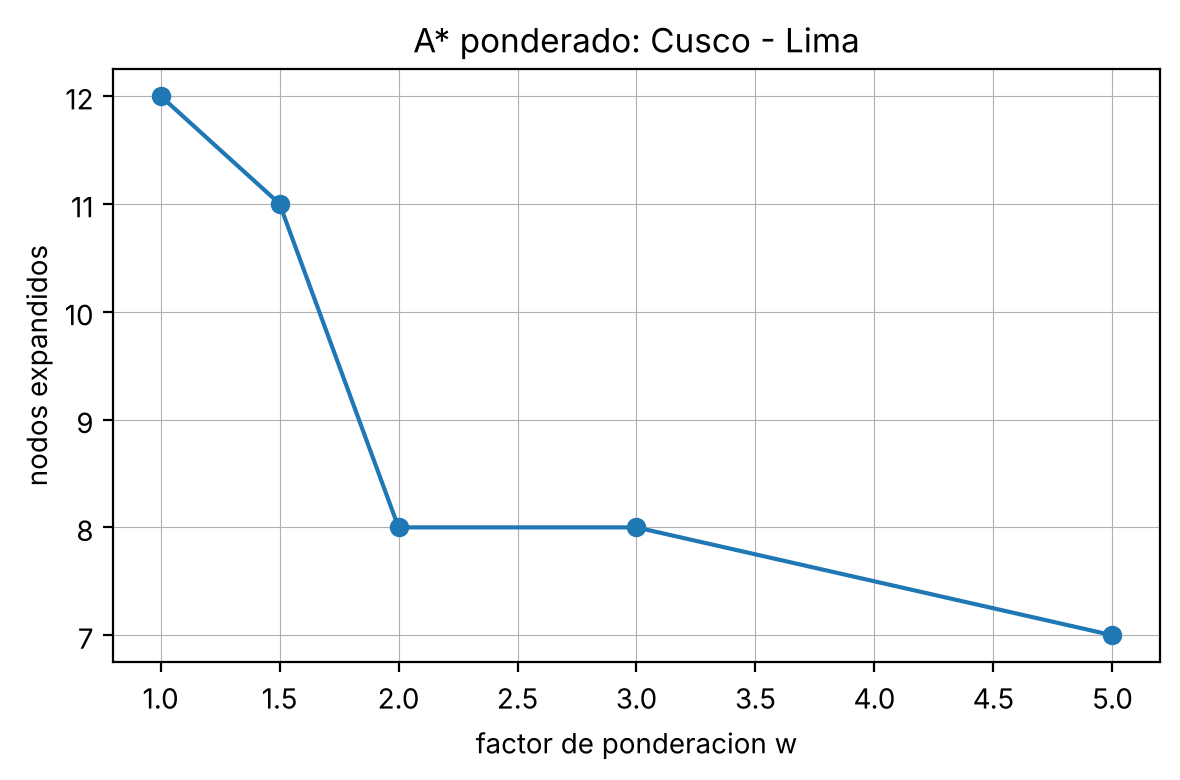

In [21]:
import matplotlib.pyplot as plt

ws = [r[0] for r in resultados_w]
expandidos = [r[2] for r in resultados_w]

plt.figure(figsize=(6, 4))
plt.plot(ws, expandidos, marker='o')
plt.xlabel('factor de ponderacion w')
plt.ylabel('nodos expandidos')
plt.title('A* ponderado: Cusco - Lima')
plt.grid(True, linewidth=0.4)
plt.tight_layout()
plt.savefig('figuras/ponderado.png', dpi=150)
plt.show()

**Interpretación de la gráfica:** al aumentar w, A\* le da más peso a la heurística y se vuelve más "codicioso": los nodos expandidos bajan de **12 (w = 1) a 11, 8, 8 y 7 (w = 5)**, una reducción de ≈ 42 %. En este problema el costo se mantiene en el óptimo (1 173 km, exceso 0 %) para todos los w. Eso es suerte del grafo y no una garantía: el teorema solo asegura C ≤ w·C\*, y esa cota (hasta 5 865 km con w = 5) está muy lejos del costo obtenido.

## Paso 11. Romper la admisibilidad

In [22]:
H_mala = dict(H)
H_mala['Ayacucho'] = 700                  # el valor real de h* es 580

no_adm, inc = verificar_heuristica(G, H_mala, 'Lima')
print('No admisibles :', no_adm)
print('Inconsistentes:', inc)

camino, costo, m = a_estrella(G, 'Cusco', 'Lima', H_mala)
print(' -> '.join(camino))
print('costo =', costo, '| expandidos =', m.expandidos)

No admisibles : ['Ayacucho']
Inconsistentes: [('Ayacucho', 'Andahuaylas'), ('Ayacucho', 'Huancavelica'), ('Ayacucho', 'Pisco')]
Cusco -> Abancay -> Puquio -> Nasca -> Ica -> Pisco -> Chincha -> Lima
costo = 1180 | expandidos = 9


In [23]:
# Traza con la heurística modificada: Ayacucho queda con f = 593 + 700 = 1293 > C* = 1173
_ = a_estrella(G, 'Cusco', 'Lima', H_mala, traza=True)

  frontera: [('Cusco', 574.0)]
  expande Cusco         g=0     h=574  f=574.0
  frontera: [('Abancay', 620.0)]
  expande Abancay       g=195   h=425  f=620.0
  frontera: [('Andahuaylas', 723.0), ('Puquio', 925.0)]
  expande Andahuaylas   g=333   h=390  f=723.0
  frontera: [('Puquio', 925.0), ('Ayacucho', 1293.0)]
  expande Puquio        g=545   h=380  f=925.0
  frontera: [('Nasca', 1020.0), ('Ayacucho', 1293.0)]
  expande Nasca         g=700   h=320  f=1020.0
  frontera: [('Ica', 1085.0), ('Ayacucho', 1293.0)]
  expande Ica           g=845   h=240  f=1085.0
  frontera: [('Pisco', 1110.0), ('Ayacucho', 1293.0)]
  expande Pisco         g=920   h=190  f=1110.0
  frontera: [('Chincha', 1145.0), ('Ayacucho', 1293.0)]
  expande Chincha       g=980   h=165  f=1145.0
  frontera: [('Lima', 1180.0), ('Ayacucho', 1293.0)]
  expande Lima          g=1180  h=0    f=1180.0


**¿Por qué sobreestimar h en un solo nodo hace que A\* descarte la mejor ruta?** Con h(Ayacucho) = 700 (h\* real = 580), Ayacucho queda con **f = g + h = 593 + 700 = 1 293**, mayor que el costo óptimo C\* = 1 173. En la traza se ve que Ayacucho entra a la frontera pero nunca sale: A\* prefiere expandir Puquio (925), Nasca (1 020), Ica (1 085), Pisco (1 110) y Chincha (1 145), llega a **Lima con f = 1 180** y, como 1 180 < 1 293, la extrae y termina con la ruta costera de **1 180 km** sin haber expandido nunca Ayacucho.

**Relación con la demostración de optimalidad:** la prueba vista en clase dice que, mientras la meta no se haya extraído, siempre hay en la frontera un nodo n de la ruta óptima con f(n) = g\*(n) + h(n) ≤ g\*(n) + h\*(n) = C\*. Esa desigualdad **usa la admisibilidad** (h ≤ h\*). Con ella, una meta subóptima con f = C > C\* nunca puede salir antes que n. Al sobreestimar h(Ayacucho), el nodo de la ruta óptima tiene f = 1 293 > C\*, la desigualdad se rompe y la meta subóptima (f = 1 180) sale primero. La función también detecta que la heurística deja de ser **consistente** en las tres aristas de Ayacucho.

---
# 5. Actividad propuesta: ampliación de la red vial al norte (Cusco → Trujillo)

### T1. Grafo ampliado  ·  T2. Heurística hacia Trujillo  ·  T3. Comparación de los cinco algoritmos

In [24]:
# T1. Grafo ampliado
filas_norte = leer_aristas('datos/rutas_peru_norte.csv')
aristas_norte = limpiar(filas_norte)
G2 = construir_grafo(aristas + aristas_norte)

print('Aristas:', len(aristas) + len(aristas_norte), '| Ciudades:', len(G2))

# T2. Heuristica hacia la nueva meta
HT = leer_heuristica('datos/heuristica_trujillo.csv')
no_adm, inc = verificar_heuristica(G2, HT, 'Trujillo')
print('Admisible :', 'SI' if not no_adm else no_adm)
print('Consistente:', 'SI' if not inc else inc)

# T3. Comparacion de los cinco algoritmos
INICIO, META = 'Cusco', 'Trujillo'
resultados = []
rutas = {}
for camino, costo, m in [bfs(G2, INICIO, META),
                         dfs(G2, INICIO, META),
                         costo_uniforme(G2, INICIO, META),
                         greedy_best_first(G2, INICIO, META, HT),
                         a_estrella(G2, INICIO, META, HT)]:
    resultados.append(m.fila(costo))
    rutas[m.nombre] = (camino, costo)
imprimir_tabla(resultados)
print()
for nombre, (camino, costo) in rutas.items():
    print(f'{nombre:15s} {costo} km: ' + ' -> '.join(camino))

Aristas: 20 | Ciudades: 18
Admisible : SI
Consistente: SI
Algoritmo           Costo (km)  Expandidos  Generados  Frontera máx.
--------------------------------------------------------------------
BFS                      1 738          18         18              3
DFS                      1 862          12         17              6
Costo uniforme           1 738          18         18              3
Greedy                   1 862          12         16              5
A*                       1 738          17         19              3

BFS             1738 km: Cusco -> Abancay -> Andahuaylas -> Ayacucho -> Pisco -> Chincha -> Lima -> Barranca -> Casma -> Chimbote -> Trujillo
DFS             1862 km: Cusco -> Abancay -> Andahuaylas -> Ayacucho -> Huancavelica -> Huancayo -> La Oroya -> Lima -> Barranca -> Casma -> Chimbote -> Trujillo
Costo uniforme  1738 km: Cusco -> Abancay -> Andahuaylas -> Ayacucho -> Pisco -> Chincha -> Lima -> Barranca -> Casma -> Chimbote -> Trujillo
Greedy      

In [25]:
# Simetría del grafo ampliado y evidencia para la pregunta 1: la decisión de Greedy en Ayacucho
for a in G2:
    for b, costo in G2[a]:
        assert (a, costo) in G2[b], f'arista asimetrica: {a}-{b}'
print('Grafo ampliado simetrico: OK')
print('\nSucesores de Ayacucho (Andahuaylas ya está cerrado):')
for v, c in G2['Ayacucho']:
    if v != 'Andahuaylas':
        print(f'  {v:13s} h_Trujillo = {HT[v]:4d} km | carretera Ayacucho-{v} = {c} km')
via_huancavelica = 245 + 147 + 125 + 187
via_pisco = 320 + 60 + 200
print(f'\nAyacucho -> Lima por Huancavelica-Huancayo-La Oroya: {via_huancavelica} km | por Pisco-Chincha: {via_pisco} km')

Grafo ampliado simetrico: OK

Sucesores de Ayacucho (Andahuaylas ya está cerrado):
  Huancavelica  h_Trujillo =  683 km | carretera Ayacucho-Huancavelica = 245 km
  Pisco         h_Trujillo =  694 km | carretera Ayacucho-Pisco = 320 km

Ayacucho -> Lima por Huancavelica-Huancayo-La Oroya: 704 km | por Pisco-Chincha: 580 km


### T4. A* ponderado sobre Cusco → Trujillo

In [26]:
C_estrella_T = 1738
resultados_wT = []
print(f"{'w':>5}{'Costo (km)':>12}{'Expandidos':>12}{'Exceso':>9}{'Cota w·C*':>11}{'¿C <= w·C*?':>13}")
for w in (1.0, 1.5, 2.0, 3.0):
    camino, costo, m = a_estrella(G2, INICIO, META, HT, w=w)
    exceso = 100 * (costo - C_estrella_T) / C_estrella_T
    resultados_wT.append((w, costo, m.expandidos, exceso))
    print(f'{w:>5}{costo:>12}{m.expandidos:>12}{exceso:>8.1f}%{w*C_estrella_T:>11.0f}{str(costo <= w*C_estrella_T):>13}')
    if w == 2.0:
        ruta_w2 = camino
print('\nRuta con w = 2:', ' -> '.join(ruta_w2))

    w  Costo (km)  Expandidos   Exceso  Cota w·C*  ¿C <= w·C*?
  1.0        1738          17     0.0%       1738         True
  1.5        1738          15     0.0%       2607         True
  2.0        1862          12     7.1%       3476         True
  3.0        1862          12     7.1%       5214         True

Ruta con w = 2: Cusco -> Abancay -> Andahuaylas -> Ayacucho -> Huancavelica -> Huancayo -> La Oroya -> Lima -> Barranca -> Casma -> Chimbote -> Trujillo


In [27]:
# Comparación de ahorros de A* frente a costo uniforme y del exceso de Greedy en ambos problemas
ahorro_L = (13 - 12) / 13 * 100
ahorro_T = (18 - 17) / 18 * 100
exceso_greedy_L = (1180 - 1173) / 1173 * 100
exceso_greedy_T = (1862 - 1738) / 1738 * 100
print(f'Ahorro de A* vs costo uniforme -> Lima: 1 nodo ({ahorro_L:.1f} %) | Trujillo: 1 nodo ({ahorro_T:.1f} %)')
print(f'Exceso de Greedy sobre el óptimo -> Lima: {exceso_greedy_L:.1f} % | Trujillo: {exceso_greedy_T:.1f} %')

g_T = costos_optimos_a(G2, 'Cusco'); hT_estrella = costos_optimos_a(G2, 'Trujillo')
razon_T = [HT[c] / hT_estrella[c] for c in G2 if hT_estrella[c]]
print(f'Razón h/h* promedio -> Lima: {sum(razones)/len(razones):.2f} | Trujillo: {sum(razon_T)/len(razon_T):.2f}')
print('Nodos con f = g* + h > C* (los únicos que A* no expande):',
      [c for c in G2 if g_T[c] + HT[c] > C_estrella_T])

Ahorro de A* vs costo uniforme -> Lima: 1 nodo (7.7 %) | Trujillo: 1 nodo (5.6 %)
Exceso de Greedy sobre el óptimo -> Lima: 0.6 % | Trujillo: 7.1 %
Razón h/h* promedio -> Lima: 0.58 | Trujillo: 0.75
Nodos con f = g* + h > C* (los únicos que A* no expande): ['Huaraz']


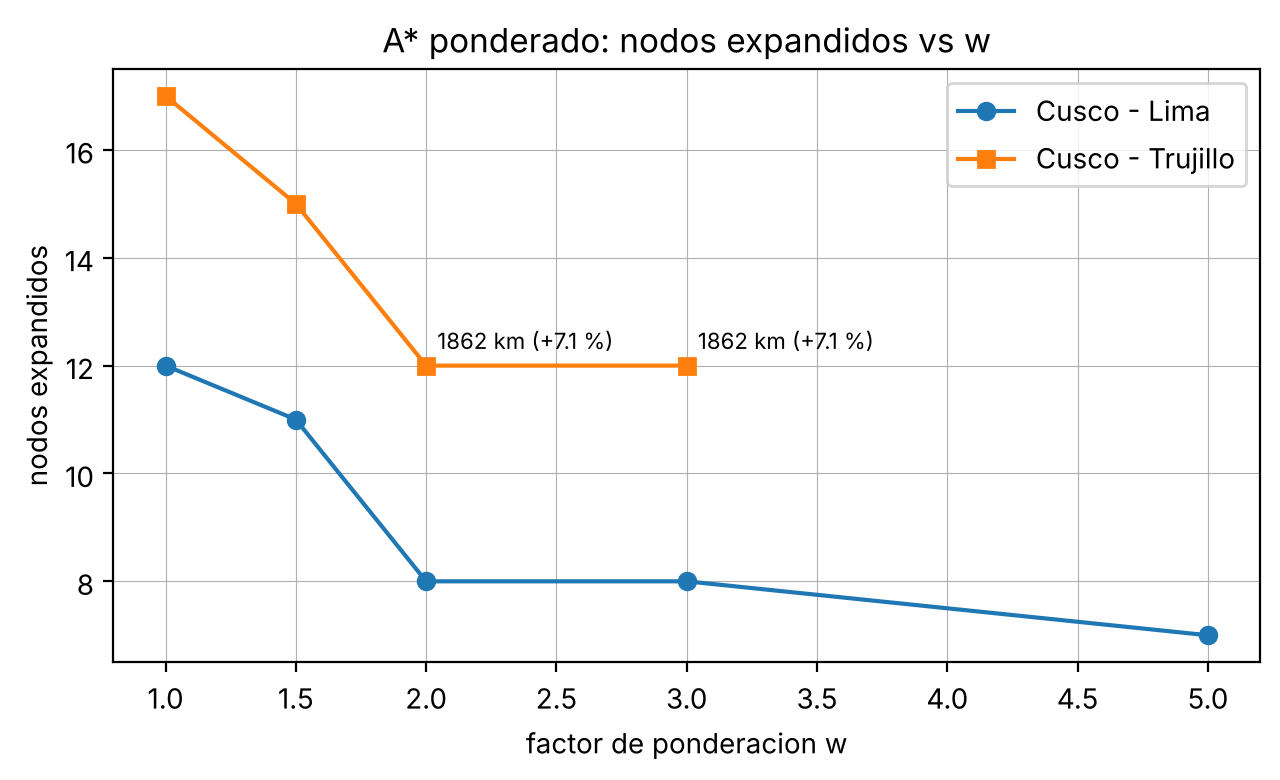

In [28]:
# Gráfica comparativa de A* ponderado en ambos problemas
plt.figure(figsize=(6.5, 4))
plt.plot([r[0] for r in resultados_w], [r[2] for r in resultados_w], marker='o', label='Cusco - Lima')
plt.plot([r[0] for r in resultados_wT], [r[2] for r in resultados_wT], marker='s', label='Cusco - Trujillo')
for w, costo, exp, exc in resultados_wT:
    if exc > 0:
        plt.annotate(f'{costo} km (+{exc:.1f} %)', (w, exp), textcoords='offset points', xytext=(4, 6), fontsize=8)
plt.xlabel('factor de ponderacion w'); plt.ylabel('nodos expandidos')
plt.title('A* ponderado: nodos expandidos vs w')
plt.grid(True, linewidth=0.4); plt.legend(); plt.tight_layout()
plt.savefig('figuras/ponderado_trujillo.png', dpi=150)
plt.show()

### T5. Análisis crítico (preguntas de la sección 5.4)

**1. ¿Encuentra Greedy la ruta óptima?** **No.** Greedy devuelve 1 862 km por el interior (…Ayacucho–**Huancavelica–Huancayo–La Oroya**–Lima–…), mientras que A\* devuelve 1 738 km por la costa (…Ayacucho–**Pisco–Chincha**–Lima–…). **Se separan en Ayacucho.** Con Andahuaylas ya cerrado, Greedy compara Huancavelica (h = **683** km a Trujillo) con Pisco (h = **694** km) y elige Huancavelica por 11 km de línea recta. Pero por carretera el tramo Ayacucho→Lima por el interior suma **704 km** (245 + 147 + 125 + 187), frente a **580 km** por la costa (320 + 60 + 200). Como Trujillo está al norte, la línea recta favorece a las ciudades del interior, aunque su camino por carretera sea más largo, y Greedy nunca mira el costo acumulado.

**2. Porcentaje de exceso de Greedy.** (1 862 − 1 738) / 1 738 = **7,1 %**, frente al **0,6 %** del problema Cusco → Lima, casi 12 veces más. En el problema hacia Lima, la decisión equivocada (Puquio) llevaba a la costa por una ruta casi igual de larga (solo +7 km). Aquí el error en Ayacucho lleva a la ruta del interior, **124 km más larga**, y una vez tomada no hay forma de "corregir" el desvío. Además, con una meta más lejana hay más decisiones donde Greedy puede equivocarse, y cada error se suma al costo final porque Greedy ignora g(n).

**3. Ahorro de A\* frente a costo uniforme.** A\* expande **17** nodos y costo uniforme **18**: ahorra **1 nodo (5,6 %)**, frente a 1 nodo (**7,7 %**) en Cusco → Lima. El único nodo descartado es **Huaraz** (f = 1 573 + 228 = 1 801 > C\* = 1 738). La heurística hacia Trujillo está algo más informada (h/h\* promedio 0,75 frente a 0,58), pero el grafo sigue siendo casi una cadena: casi todas las ciudades están en el camino hacia la meta y tienen f < C\*. Como el grafo creció, el ahorro relativo es incluso menor.

**4. Comportamiento nuevo en A\* ponderado.** **A partir de w = 2, A\* ponderado devuelve una ruta subóptima**: 1 862 km (**+7,1 %**), la misma ruta del interior que Greedy y con los mismos 12 expandidos. Con w = 1,5 todavía encuentra el óptimo (1 738 km) expandiendo 15 nodos. **La cota se respeta:** con w = 2, C = 1 862 ≤ 2 × 1 738 = 3 476; con w = 3, 1 862 ≤ 5 214. El teorema solo garantiza esa cota, no el óptimo, y aquí "la suerte se acabó", como anticipaba la guía.

**5. Recomendación para el área de operaciones.** Recomiendo poner en producción **A\* clásico (w = 1) con la heurística de distancia en línea recta**. En los dos corredores encontró siempre la ruta óptima, verificada contra costo uniforme, con incluso un poco menos de trabajo, y la heurística se comprobó admisible y consistente. Greedy y A\* con w ≥ 2 ahorran unos pocos nodos, pero ya produjeron rutas 7 % más caras (124 km extra por viaje). Cambiaría de opinión si la red crece a miles de ciudades y el tiempo de respuesta se vuelve crítico; en ese caso usaría A\* ponderado con w ≈ 1,5, que aquí siguió siendo óptimo y garantiza no pasar de 1,5·C\*. Si la heurística dejara de ser admisible, por ejemplo con estimaciones basadas en tiempos que pueden sobreestimar, volvería a costo uniforme.